
Fashion-MNIST Class Names:
0 = T-shirt/top
1 = Trouser
2 = Pullover
3 = Dress
4 = Coat
5 = Sandal
6 = Shirt
7 = Sneaker
8 = Bag
9 = Ankle boot

Total Images in the Fashion-MNISt Dataset: 60000
Train Size: 54000
Validation Size: 6000

CNN Model:
FashionCNN(
  (convolution_layer_1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (convolution_layer_2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)

Batch images: torch.Size([64, 1, 28, 28])
Batch labels: torch.Size([64])

Final output: torch.Size([64, 10])
Epoch [1/10] Training Loss: 0.5498 Training Accuracy: 80.51% Validation Loss: 0.3578 Validation Accuracy: 86.95%
Epoch [2/10] Training Loss: 0.3640 Training Accuracy: 86.82% Valida

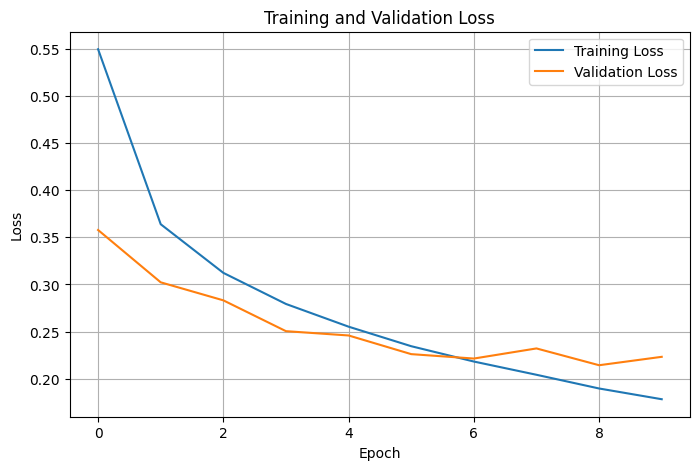

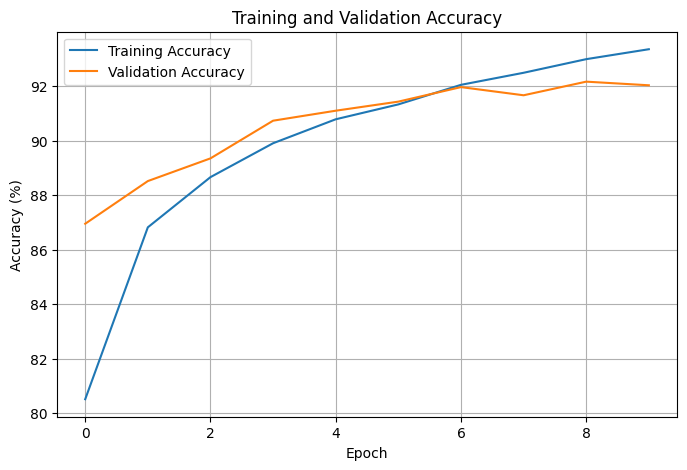

Test Accuracy: 91.82%

Classification Report
              precision    recall  f1-score   support

 T-shirt/top       0.86      0.88      0.87      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.89      0.84      0.87      1000
       Dress       0.89      0.93      0.91      1000
        Coat       0.86      0.89      0.88      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.78      0.74      0.76      1000
     Sneaker       0.95      0.98      0.96      1000
         Bag       0.99      0.98      0.99      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000


Confusion Matrix:
[[884   1  16  24   1   1  67   0   6   0]
 [  1 982   0   9   2   0   5   0   1   0]
 [ 18   1 840  12  62   0  67   0   0   0]
 [ 12   1   4 932  28   0  23   0   0   0]
 [  0

<Figure size 1000x800 with 0 Axes>

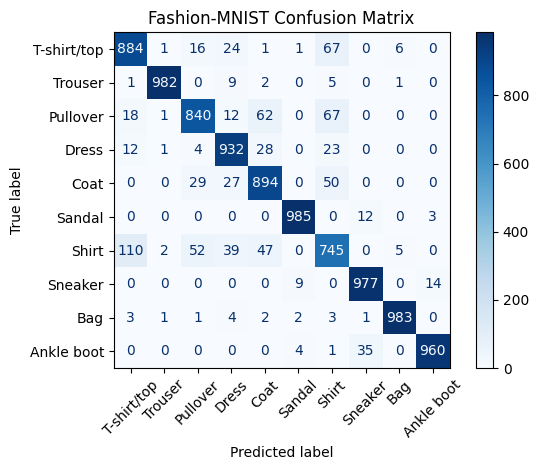

In [23]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, random_split

import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

#Data Preprocessing
transform = transforms.Compose([ transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,)), ])

#Load Fashion-MNIST Dataset
train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

#Print Class names
class_names = train_dataset.classes
print("\nFashion-MNIST Class Names:")
for label, name in enumerate(class_names):
    print(label, "=", name)

#Train and Validation Split
total_size = len(train_dataset)
print("\nTotal Images in the Fashion-MNISt Dataset:",total_size)
train_size = int(0.9 * total_size)
validation_size = total_size - train_size
print("Train Size:",train_size)
print("Validation Size:",validation_size)

train_dataset, validation_dataset = random_split(
    train_dataset,
    [train_size, validation_size],
    generator=torch.Generator().manual_seed(42)
)

#Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=64,
    shuffle=False
)
test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

#Create CNN Model
class FashionCNN(nn.Module):

    def __init__(self):
        super().__init__()
        # First convolution layer
        self.convolution_layer_1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3,
            padding=1
        )
        # Second convolution layer
        self.convolution_layer_2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )
        # Max pooling
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )
        # Fully connected layer
        self.fc1 = nn.Linear(64*7*7, 128)
        # Dropout
        self.dropout = nn.Dropout(0.5)
        # Output layer
        self.fc2 = nn.Linear(128, 10)
        # ReLU activation
        self.relu = nn.ReLU()


    def forward(self, x):
        # First convolution
        x = self.convolution_layer_1(x)
        x = self.relu(x)
        x = self.pool(x)

        # Second convolution
        x = self.convolution_layer_2(x)
        x = self.relu(x)
        x = self.pool(x)

        # Flatten
        x = x.view(x.size(0), -1)

        # Fully connected layer
        x = self.fc1(x)

        x = self.relu(x)
        # Dropout
        x = self.dropout(x)
        # Output
        x = self.fc2(x)

        return x

#Create Model
model = FashionCNN()

print("\nCNN Model:")
print(model)
# Get one batch
images, labels = next(iter(train_loader))
print("\nBatch images:", images.shape)
print("Batch labels:", labels.shape)

# Pass images through CNN
output = model(images)
print("\nFinal output:", output.shape)

#Loss Function
criterion = nn.CrossEntropyLoss()

#Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

#Training the model no. of Times & Train the Model
number_of_epochs = 10

train_losses = []
validation_losses = []

train_accuracies = []
validation_accuracies = []

for epoch in range(number_of_epochs):
    model.train()
    total_training_loss = 0
    correct_predictions = 0
    total_training_images = 0

    #Trainig Model
    for images, labels in train_loader:
        # Clear previous gradients
        optimizer.zero_grad()
        # Forward pass
        outputs = model(images)
        # Calculate loss
        loss = criterion(outputs, labels)
        # Backpropagation
        loss.backward()
        # Update model weights
        optimizer.step()
        # Add loss
        total_training_loss += loss.item()
        # Find predicted class
        _, predicted = torch.max(outputs, 1)
        # Count correct predictions
        total_training_images += labels.size(0)
        correct_predictions += (predicted == labels).sum().item()
    # Calculate average training loss
    training_loss = (total_training_loss / len(train_loader))
    # Calculate training accuracy
    training_accuracy = (100 * correct_predictions / total_training_images)


    # Validation
    model.eval()

    total_validation_loss = 0
    correct_validation_predictions = 0
    total_validation_images = 0
    with torch.no_grad():
        for images, labels in validation_loader:
            # Forward pass
            outputs = model(images)
            # Calculate loss
            loss = criterion(outputs, labels)
            total_validation_loss += loss.item()
            # Prediction
            _, predicted = torch.max(outputs, 1)
            # Count predictions
            total_validation_images += labels.size(0)
            correct_validation_predictions += (predicted == labels).sum().item()
    # Average validation loss
    validation_loss = (total_validation_loss / len(validation_loader))
    # Validation accuracy
    validation_accuracy = (100 * correct_validation_predictions / total_validation_images)
    # Store values
    train_losses.append(training_loss)
    validation_losses.append(validation_loss)
    train_accuracies.append(training_accuracy)
    validation_accuracies.append(validation_accuracy)


    # Print results
    print(
        f"Epoch [{epoch + 1}/{number_of_epochs}] "
        f"Training Loss: {training_loss:.4f} "
        f"Training Accuracy: {training_accuracy:.2f}% "
        f"Validation Loss: {validation_loss:.4f} "
        f"Validation Accuracy: {validation_accuracy:.2f}%"
    )


#visualization Plot Training and Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(validation_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

#visualization Plot Training and Validation Accuracy
plt.figure(figsize=(8, 5))
plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(validation_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

#Test the Model
model.eval()
correct_predictions = 0
total_test_images = 0
all_predictions = []
all_actual_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        # Get output
        outputs = model(images)
        # Get predicted class
        _, predicted = torch.max(outputs, 1)
        # Calculate accuracy
        total_test_images += labels.size(0)
        correct_predictions += (predicted == labels).sum().item()
        # Save predictions
        all_predictions.extend(predicted.numpy())
        all_actual_labels.extend(labels.numpy())
# Calculate test accuracy
test_accuracy = (100 * correct_predictions / total_test_images)
print("\nTest Accuracy:", f"{test_accuracy:.2f}%")

# Classification Report
print("\nClassification Report")
classification_repo = classification_report(
    all_actual_labels,
    all_predictions,
    target_names=class_names
)
print(classification_repo)

# Confusion Matrix
print("\nConfusion Matrix:")
confusion = confusion_matrix(
    all_actual_labels,
    all_predictions
)
print(confusion)

#visualization Confusion Matrix
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=class_names
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Fashion-MNIST Confusion Matrix")
plt.tight_layout()
plt.show()